In [6]:
import pandas as pd

import numpy as np
from scipy.stats import spearmanr, pearsonr, kendalltau
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error, explained_variance_score, max_error

from rogi import RoughnessIndex

from multifidelity_end2end import create_low_fidelity
import argparse

from rdkit import Chem
from rdkit.Chem import Descriptors

/home/kpg/miniconda3/envs/chemprop/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Define Metrics

In [7]:
def calculate_percentage_metrics(list1, list2):
    arr1 = np.array(list1)
    arr2 = np.array(list2)
    
    # Avoid division by zero; handle cases where actual values are zero
    arr1_safe = np.where(arr1 == 0, np.finfo(float).eps, arr1)  # Replace 0 with a very small number
    
    # Calculate MAPE - Mean Absolute Percentage Error
    mape = np.mean(np.abs((arr1 - arr2) / arr1_safe)) * 100
    
    # Calculate wMAPE - Weighted Mean Absolute Percentage Error
    wmape = np.sum(np.abs(arr1 - arr2)) / np.sum(arr1_safe) * 100
    
    # Include previous metrics for completeness
    mae = mean_absolute_error(arr1, arr2)
    mse = mean_squared_error(arr1, arr2)
    rmse = np.sqrt(mse)
    r_squared = r2_score(arr1, arr2)
    median_ae = median_absolute_error(arr1, arr2)
    explained_variance = explained_variance_score(arr1, arr2)
    max_err = max_error(arr1, arr2)
    spearman_corr, _ = spearmanr(arr1, arr2)
    pearson_corr, _ = pearsonr(arr1, arr2)
    kendall_corr, _ = kendalltau(arr1, arr2)
    covariance_matrix = np.cov(arr1, arr2)
    covariance = covariance_matrix[0, 1]
    corrcoef_matrix = np.corrcoef(arr1, arr2)
    corrcoef = corrcoef_matrix[0, 1]

    
    # Print results
    print(f"MAPE (Mean Absolute Percentage Error): {mape}%")
    print(f"wMAPE (Weighted Mean Absolute Percentage Error): {wmape}%")
    print(f"MAE (Mean Absolute Error): {mae}")
    print(f"RMSE (Root Mean Squared Error): {rmse}")
    print(f"R-squared: {r_squared}")
    print(f"Median Absolute Error: {median_ae}")
    print(f"Explained Variance Score: {explained_variance}")
    print(f"Max Error: {max_err}")
    print(f"Spearman's rank correlation: {spearman_corr}")
    print(f"Pearson correlation coefficient: {pearson_corr}")
    print(f"Kendall Tau correlation: {kendall_corr}")
    print(f"Covariance: {covariance}")
    print(f"Correlation coefficient: {corrcoef}")

    return mape, wmape, mae, rmse, r_squared, median_ae, explained_variance, max_err, spearman_corr, pearson_corr, kendall_corr, covariance, corrcoef

In [8]:
def compute_rogis(hf, lf, smiles, X=None, metric='tanimoto', verbose=False):
    ri_hf = RoughnessIndex(Y=hf, X=X, smiles=smiles, metric=metric, verbose=verbose)
    rogi_hf = ri_hf.compute_index()
    print(f"ROGI for HF: {rogi_hf}")
    ri_lf = RoughnessIndex(Y=lf, X=X, smiles=smiles, metric=metric, verbose=verbose)
    rogi_lf = ri_lf.compute_index()
    print(f"ROGI for LF: {rogi_lf}")
    ri_diff = RoughnessIndex(Y=hf-lf, X=X, smiles=smiles, metric=metric, verbose=verbose)
    rogi_diff = ri_diff.compute_index()
    print(f"ROGI for HF-LF: {rogi_diff}")
    ri_absdiff = RoughnessIndex(Y=abs(hf-lf), X=X, smiles=smiles, metric=metric, verbose=verbose)
    rogi_absdiff = ri_absdiff.compute_index()
    print(f"ROGI for |HF-LF|: {rogi_absdiff}")
    
    return rogi_hf, rogi_lf, rogi_diff, rogi_absdiff

# Prepare Data

In [9]:
df = pd.read_csv('tests/data/gdb11_0.001.csv')
df.rename(columns={'h298': 'h298_HF'}, inplace=True)
df

,smiles,h298_HF
0,N#CC(=C(N)C=O)C1CCC1,4.071
1,CNC1C(O)C=CC1N(C)C,0.915
2,C1=CC23CCOCC2C1CC3,25.393
3,CC1(C)COC12CCNC2=N,12.184
4,COCC1CC2CC(N2)C1C,-4.939
...,...,...
7111,CC(CN)N(C)C(=N)CCN,2.539
7112,OC1CC2C=CC=CC(C1)O2,-35.418
7113,NC1C2CC(O)CC1(CO)C2,-41.236
7114,CCC1=CC2C3CC2C1(N)C3,67.317


In [10]:
# args = argparse.Namespace()

# args.lf_col_name = 'h298_LF'
# args.hf_col_name = 'h298_HF'
# args.add_pn_bias_to_make_lf = 0
# args.add_constant_bias_to_make_lf = 0.0
# args.add_gauss_noise_to_make_lf = 5.0
# args.add_descriptor_bias_to_make_lf = 0.0
# args.seed = 0

# df = create_low_fidelity(df, args)
# df

# Calculate Metrics with Fingerprints

In [11]:
# calculate_percentage_metrics(df['h298_HF'], df['h298_LF'])

In [12]:
# rogi_hf, rogi_lf, rogi_diff, rogi_absdiff = compute_rogis(df['h298_HF'], df['h298_LF'], df['smiles'])

# Calculate Metrics with Descriptors

In [13]:
def getMolDescriptors(mol, missingVal=None):
    ''' calculate the full list of descriptors for a molecule
    
        missingVal is used if the descriptor cannot be calculated
    '''
    res = {}
    for nm,fn in Descriptors._descList:
        # some of the descriptor fucntions can throw errors if they fail, catch those here:
        try:
            val = fn(mol)
        except:
            # print the error message:
            import traceback
            traceback.print_exc()
            # and set the descriptor value to whatever missingVal is
            val = missingVal
        res[nm] = val
    return res

smiles = df.smiles
mols = [Chem.MolFromSmiles(smi) for smi in smiles]

allDescrs = [getMolDescriptors(m) for m in mols]
desc_df = pd.DataFrame(allDescrs)
desc_df

,MaxEStateIndex,MinEStateIndex,MaxAbsEStateIndex,MinAbsEStateIndex,qed,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,NumRadicalElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,10.215671,0.108519,10.215671,0.108519,0.358071,150.181,140.101,150.079313,58,0,...,0,0,0,0,0,0,0,0,0,0
1,9.432269,-0.340370,9.432269,0.143519,0.525830,156.229,140.101,156.126263,64,0,...,0,0,0,0,0,0,0,0,0,0
2,5.519005,0.600116,5.519005,0.600116,0.479740,150.221,136.109,150.104465,60,0,...,0,0,0,0,0,0,0,0,0,0
3,7.673403,-0.256944,7.673403,0.160301,0.540563,154.213,140.101,154.110613,62,0,...,0,0,0,0,0,0,0,0,0,0
4,5.192824,0.799907,5.192824,0.799907,0.642546,155.241,138.105,155.131014,64,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7111,7.518750,0.230602,7.518750,0.230602,0.384259,158.249,140.105,158.153147,66,0,...,0,0,0,0,0,0,0,0,0,0
7112,9.392222,-0.188750,9.392222,0.123843,0.561251,152.193,140.097,152.083730,60,0,...,0,0,0,0,0,0,0,0,0,0
7113,9.357431,-0.221574,9.357431,0.122685,0.478985,157.213,142.093,157.110279,64,0,...,0,0,0,0,0,0,0,0,0,0
7114,6.371667,0.170718,6.371667,0.170718,0.564014,149.237,134.117,149.120449,60,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
# list which columns in desc_df have NaN values
print(desc_df.columns[desc_df.isna().any()].tolist())
print(len(desc_df.columns[desc_df.isna().any()].tolist()))

# drop columns with NaN values
desc_df = desc_df.dropna(axis=1)

[]
0


In [15]:
# print('Euclidean distance')
# rogi_hf_desc_euc, rogi_lf_desc_euc, rogi_diff_desc_euc, rogi_absdiff_desc_euc = compute_rogis(df['h298_HF'], df['h298_LF'], df['smiles'], X=desc_df, metric='euclidean')
# print()
# print('Cosine distance')
# rogi_hf_desc_cos, rogi_lf_desc_cos, rogi_diff_desc_cos, rogi_absdiff_desc_cos = compute_rogis(df['h298_HF'], df['h298_LF'], df['smiles'], X=desc_df, metric='cosine')

# Bulk

In [19]:
noises_and_biases = [
    [0, 0.0, 0.0, 0.0],

    [1, 0.0, 0.0, 0.0],
    [2, 0.0, 0.0, 0.0],
    [3, 0.0, 0.0, 0.0],

    [0, 10.0, 0.0, 0.0],
    [0, 50.0, 0.0, 0.0],

    [0, 0.0, 10.0, 0.0],
    [0, 0.0, 50.0, 0.0],

    [0, 0.0, 0.0, 10.0],
    [0, 0.0, 0.0, 50.0],
    ]

# create a dataframe to store the results
column_list = ['add_pn_bias_to_make_lf', 'add_constant_bias_to_make_lf', 'add_gauss_noise_to_make_lf', 
                'add_descriptor_bias_to_make_lf', 'mape', 'wmape', 'mae', 'rmse', 'r_squared', 'median_ae', 
                'explained_variance', 'max_err', 'spearman_corr', 'pearson_corr', 'kendall_corr', 'covariance', 
                'corrcoef', 'rogi_hf', 'rogi_lf', 'rogi_diff', 'rogi_absdiff', 'rogi_hf_desc_euc', 'rogi_lf_desc_euc', 
                'rogi_diff_desc_euc', 'rogi_absdiff_desc_euc', 'rogi_hf_desc_cos', 'rogi_lf_desc_cos', 'rogi_diff_desc_cos', 'rogi_absdiff_desc_cos']
results_df = pd.DataFrame(columns=column_list)
                       
for noise_and_bias in noises_and_biases:
    df = pd.read_csv('tests/data/gdb11_0.001.csv')
    df.rename(columns={'h298': 'h298_HF'}, inplace=True)

    args = argparse.Namespace()

    args.lf_col_name = 'h298_LF'
    args.hf_col_name = 'h298_HF'
    args.add_pn_bias_to_make_lf = noise_and_bias[0]
    args.add_constant_bias_to_make_lf = noise_and_bias[1]
    args.add_gauss_noise_to_make_lf = noise_and_bias[2]
    args.add_descriptor_bias_to_make_lf = noise_and_bias[3]
    args.seed = 0

    df.set_index('smiles', inplace=True)
    df = create_low_fidelity(df, args)
    df.reset_index(inplace=True)
    
    print(f'Noise and bias: {noise_and_bias}')
    print("Percentage Metrics")
    mape, wmape, mae, rmse, r_squared, median_ae, explained_variance, \
        max_err, spearman_corr, pearson_corr, kendall_corr, covariance, corrcoef = calculate_percentage_metrics(df['h298_HF'], df['h298_LF'])
    print()
    print("ROGIs")
    rogi_hf, rogi_lf, rogi_diff, rogi_absdiff = compute_rogis(df['h298_HF'], df['h298_LF'], df['smiles'])
    print()
    print('Euclidean distance - descriptors')
    rogi_hf_desc_euc, rogi_lf_desc_euc, rogi_diff_desc_euc, rogi_absdiff_desc_euc = compute_rogis(df['h298_HF'], df['h298_LF'], df['smiles'], X=desc_df, metric='euclidean')
    print()
    print('Cosine distance - descriptors')
    rogi_hf_desc_cos, rogi_lf_desc_cos, rogi_diff_desc_cos, rogi_absdiff_desc_cos = compute_rogis(df['h298_HF'], df['h298_LF'], df['smiles'], X=desc_df, metric='cosine')
    print()
    print()

    # store all the results in a dataframe
    results_df = pd.concat([results_df, pd.DataFrame([[noise_and_bias[0], noise_and_bias[1], noise_and_bias[2], noise_and_bias[3],
                                             mape, wmape, mae, rmse, r_squared, median_ae, explained_variance, 
                                             max_err, spearman_corr, pearson_corr, kendall_corr, covariance, corrcoef,
                                             rogi_hf, rogi_lf, rogi_diff, rogi_absdiff, rogi_hf_desc_euc, rogi_lf_desc_euc, 
                                             rogi_diff_desc_euc, rogi_absdiff_desc_euc, rogi_hf_desc_cos, rogi_lf_desc_cos, 
                                             rogi_diff_desc_cos, rogi_absdiff_desc_cos]], columns=column_list)])   

results_df

Noise and bias: [0, 0.0, 0.0, 0.0]
Percentage Metrics
MAPE (Mean Absolute Percentage Error): 0.0%
wMAPE (Weighted Mean Absolute Percentage Error): -0.0%
MAE (Mean Absolute Error): 0.0
RMSE (Root Mean Squared Error): 0.0
R-squared: 1.0
Median Absolute Error: 0.0
Explained Variance Score: 1.0
Max Error: 0.0
Spearman's rank correlation: 1.0
Pearson correlation coefficient: 1.0
Kendall Tau correlation: 1.0
Covariance: 3608.5328893861188
Correlation coefficient: 1.0

ROGIs
ROGI for HF: 0.02187742214546992
ROGI for LF: 0.02187742214546992
ROGI for HF-LF: 0.0
ROGI for |HF-LF|: 0.0

Euclidean distance
ROGI for HF: 0.20940144662277976
ROGI for LF: 0.20940144662277976
ROGI for HF-LF: 0.0
ROGI for |HF-LF|: 0.0

Cosine distance
ROGI for HF: 0.23403254146317282
ROGI for LF: 0.23403254146317282
ROGI for HF-LF: 0.0
ROGI for |HF-LF|: 0.0


Noise and bias: [1, 0.0, 0.0, 0.0]
Percentage Metrics
MAPE (Mean Absolute Percentage Error): 8.83353849916781%
wMAPE (Weighted Mean Absolute Percentage Error): -73.

100%|██████████| 13/13 [00:10<00:00,  1.25it/s]


Noise and bias: [0, 0.0, 0.0, 10.0]
Percentage Metrics
MAPE (Mean Absolute Percentage Error): 126.22274870564425%
wMAPE (Weighted Mean Absolute Percentage Error): -538.0637933653992%
MAE (Mean Absolute Error): 11.747921993427957
RMSE (Root Mean Squared Error): 14.879639817384602
R-squared: 0.9386357819762498
Median Absolute Error: 10.001747109085137
Explained Variance Score: 0.9386357819762498
Max Error: 69.85770555752791
Spearman's rank correlation: 0.9776984110215057
Pearson correlation coefficient: 0.9806461701719777
Kendall Tau correlation: 0.874850733637323
Covariance: 4007.239239509872
Correlation coefficient: 0.9806461701719776

ROGIs
ROGI for HF: 0.02187742214546992
ROGI for LF: 0.02121499419696571
ROGI for HF-LF: 0.019602205690946284
ROGI for |HF-LF|: 0.03141185707098318

Euclidean distance
ROGI for HF: 0.20940144662277976
ROGI for LF: 0.20468533027392333
ROGI for HF-LF: 0.2089089289384588
ROGI for |HF-LF|: 0.23214765674264387

Cosine distance
ROGI for HF: 0.23403254146317282


100%|██████████| 13/13 [00:10<00:00,  1.26it/s]


Noise and bias: [0, 0.0, 0.0, 50.0]
Percentage Metrics
MAPE (Mean Absolute Percentage Error): 927.2707408620809%
wMAPE (Weighted Mean Absolute Percentage Error): -3922.099104768217%
MAE (Mean Absolute Error): 85.63392464138555
RMSE (Root Mean Squared Error): 106.17426513548966
R-squared: -2.1244162983263926
Median Absolute Error: 74.01468668283829
Explained Variance Score: -2.124416298326392
Max Error: 398.61264504482426
Spearman's rank correlation: 0.6218395608004658
Pearson correlation coefficient: 0.6287700638964218
Kendall Tau correlation: 0.447831128210812
Covariance: 5028.300760556311
Correlation coefficient: 0.6287700638964219

ROGIs
ROGI for HF: 0.02187742214546992
ROGI for LF: 0.021391796328030954
ROGI for HF-LF: 0.018522340789243974
ROGI for |HF-LF|: 0.03173750003628861

Euclidean distance
ROGI for HF: 0.20940144662277976
ROGI for LF: 0.24949801234180433
ROGI for HF-LF: 0.24075691031705615
ROGI for |HF-LF|: 0.2795637016225251

Cosine distance
ROGI for HF: 0.23403254146317282


,add_pn_bias_to_make_lf,add_constant_bias_to_make_lf,add_gauss_noise_to_make_lf,add_descriptor_bias_to_make_lf,mape,wmape,mae,rmse,r_squared,median_ae,...,rogi_diff,rogi_absdiff,rogi_hf_desc_euc,rogi_lf_desc_euc,rogi_diff_desc_euc,rogi_absdiff_desc_euc,rogi_hf_desc_cos,rogi_lf_desc_cos,rogi_diff_desc_cos,rogi_absdiff_desc_cos
0,0,0.0,0.0,0.0,0.000000,-0.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000e+00,0.000000e+00,0.209401,0.209401,0.000000e+00,0.000000e+00,0.234033,0.234033,0.000000e+00,0.000000e+00
0,1,0.0,0.0,0.0,8.833538,-73.807053,1.611481,2.053020,0.998832,1.340574,...,2.187742e-02,3.262775e-02,0.209401,0.209401,2.094014e-01,2.484308e-01,0.234033,0.234033,2.340325e-01,2.564840e-01
0,2,0.0,0.0,0.0,4224.646748,-146657.832943,3202.082731,5768.304114,-9221.032853,1435.170839,...,1.946244e-02,1.946244e-02,0.209401,0.136027,1.361218e-01,1.361218e-01,0.234033,0.145887,1.462658e-01,1.462658e-01
0,3,0.0,0.0,0.0,9823.697337,-447414.261159,9768.707547,27497.795717,-209567.560129,1453.677582,...,8.531714e-03,1.182734e-02,0.209401,0.064995,6.504403e-02,8.500181e-02,0.234033,0.070369,7.042851e-02,8.924172e-02
0,0,10.0,0.0,0.0,112.081264,-458.007632,10.000000,10.000000,0.972284,10.000000,...,4.444163e-16,4.444163e-16,0.209401,0.209401,2.371722e-15,2.371722e-15,0.234033,0.234033,2.498339e-15,2.498339e-15
0,0,50.0,0.0,0.0,560.406318,-2290.038160,50.000000,50.000000,0.307100,50.000000,...,1.303318e-15,1.303318e-15,0.209401,0.209401,6.639605e-15,6.639605e-15,0.234033,0.234033,6.943171e-15,6.943171e-15
0,0,0.0,10.0,0.0,86.843971,-360.971079,7.881333,9.878819,0.972952,6.725218,...,4.934781e-02,6.096537e-02,0.209401,0.214761,2.515192e-01,3.000209e-01,0.234033,0.239593,2.572308e-01,3.095828e-01
0,0,0.0,50.0,0.0,434.219856,-1804.855393,39.406666,49.394095,0.323792,33.626089,...,4.934781e-02,6.096537e-02,0.209401,0.233826,2.515192e-01,3.000209e-01,0.234033,0.254779,2.572308e-01,3.095828e-01
0,0,0.0,0.0,10.0,126.222749,-538.063793,11.747922,14.879640,0.938636,10.001747,...,1.960221e-02,3.141186e-02,0.209401,0.204685,2.089089e-01,2.321477e-01,0.234033,0.229030,2.263636e-01,2.446232e-01
0,0,0.0,0.0,50.0,927.270741,-3922.099105,85.633925,106.174265,-2.124416,74.014687,...,1.852234e-02,3.173750e-02,0.209401,0.249498,2.407569e-01,2.795637e-01,0.234033,0.283743,2.673321e-01,2.917826e-01


In [20]:
# results_df[['ri_hf', 'ri_lf', 'ri_diff', 'ri_absdiff', 
#             'ri_hf_desc_euc', 'ri_lf_desc_euc', 'ri_diff_desc_euc', 'ri_absdiff_desc_euc',
#             'ri_hf_desc_cos', 'ri_lf_desc_cos', 'ri_diff_desc_cos', 'ri_absdiff_desc_cos',]].apply(lambda x: x.compute_index(), axis=1)

# results_df.rename(columns={
#     'ri_hf': 'rogi_hf', 'ri_lf': 'rogi_lf', 'ri_diff': 'rogi_diff', 'ri_absdiff': 'rogi_absdiff',
#     'ri_hf_desc_euc': 'rogi_hf_desc_euc', 'ri_lf_desc_euc': 'rogi_lf_desc_euc', 'ri_diff_desc_euc': 'rogi_diff_desc_euc', 'ri_absdiff_desc_euc': 'rogi_absdiff_desc_euc',
#     'ri_hf_desc_cos': 'rogi_hf_desc_cos', 'ri_lf_desc_cos': 'rogi_lf_desc_cos', 'ri_diff_desc_cos': 'rogi_diff_desc_cos', 'ri_absdiff_desc_cos': 'rogi_absdiff_desc_cos',
# }, inplace=True)

# results_df

In [21]:
results_df.to_csv('h298_dataset_analysis_results.csv', index=False)

# Plots

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
results_df = pd.read_csv('h298_dataset_analysis_results.csv')

In [7]:
results_df.iloc[[0,1,7]]

,add_pn_bias_to_make_lf,add_constant_bias_to_make_lf,add_gauss_noise_to_make_lf,add_descriptor_bias_to_make_lf,mape,wmape,mae,rmse,r_squared,median_ae,...,rogi_diff,rogi_absdiff,rogi_hf_desc_euc,rogi_lf_desc_euc,rogi_diff_desc_euc,rogi_absdiff_desc_euc,rogi_hf_desc_cos,rogi_lf_desc_cos,rogi_diff_desc_cos,rogi_absdiff_desc_cos
0,0,0.0,0.0,0.0,0.000000,-0.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.209401,0.209401,0.000000,0.000000,0.234033,0.234033,0.000000,0.000000
1,1,0.0,0.0,0.0,8.833538,-73.807053,1.611481,2.053020,0.998832,1.340574,...,0.021877,0.032628,0.209401,0.209401,0.209401,0.248431,0.234033,0.234033,0.234033,0.256484
7,0,0.0,50.0,0.0,434.219856,-1804.855393,39.406666,49.394095,0.323792,33.626089,...,0.049348,0.060965,0.209401,0.233826,0.251519,0.300021,0.234033,0.254779,0.257231,0.309583


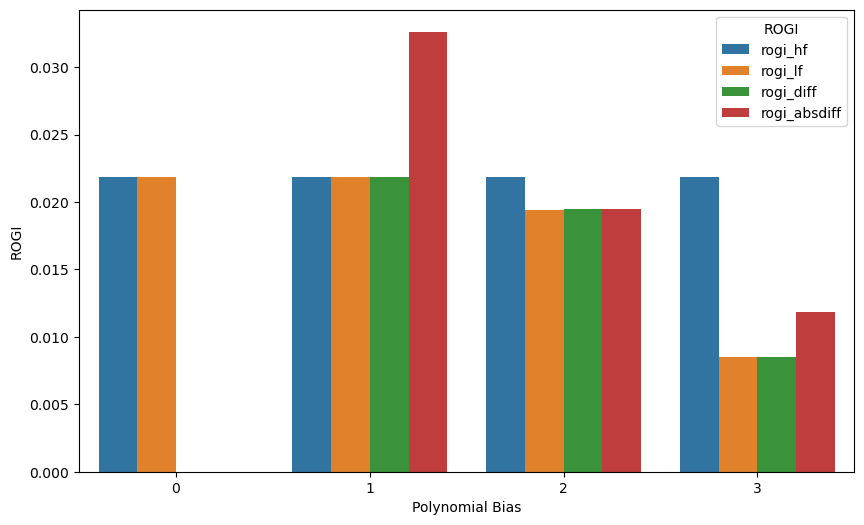

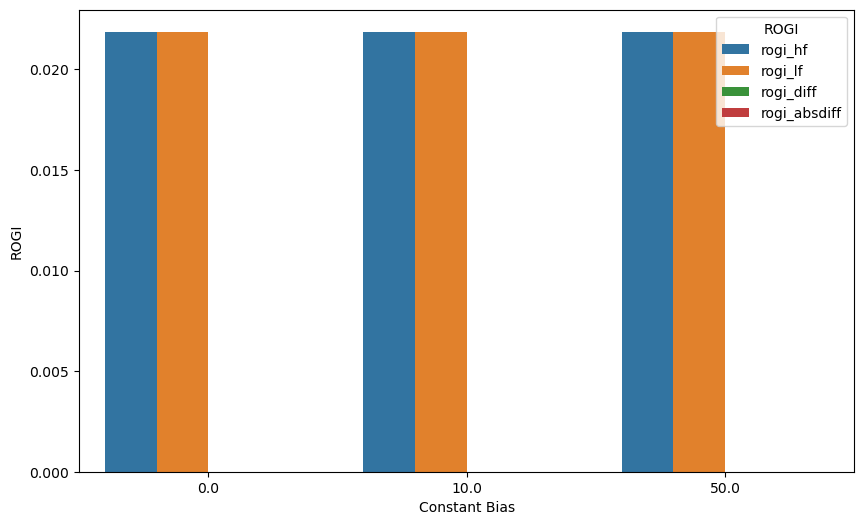

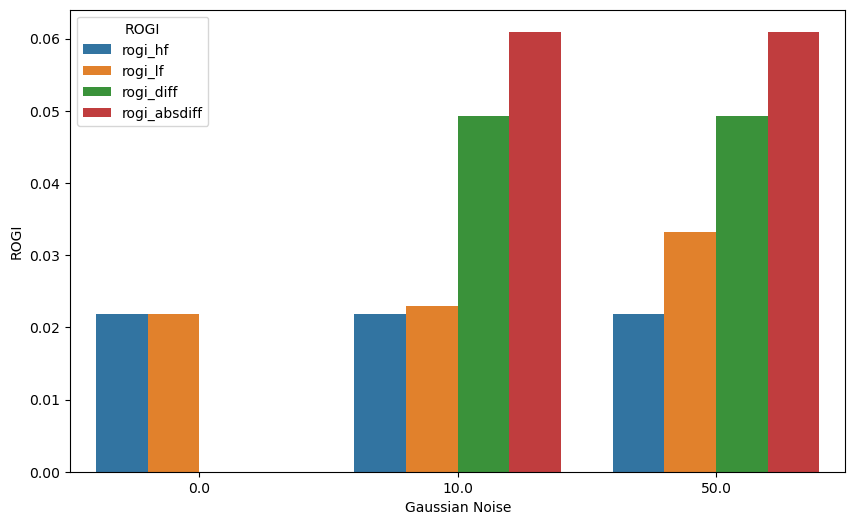

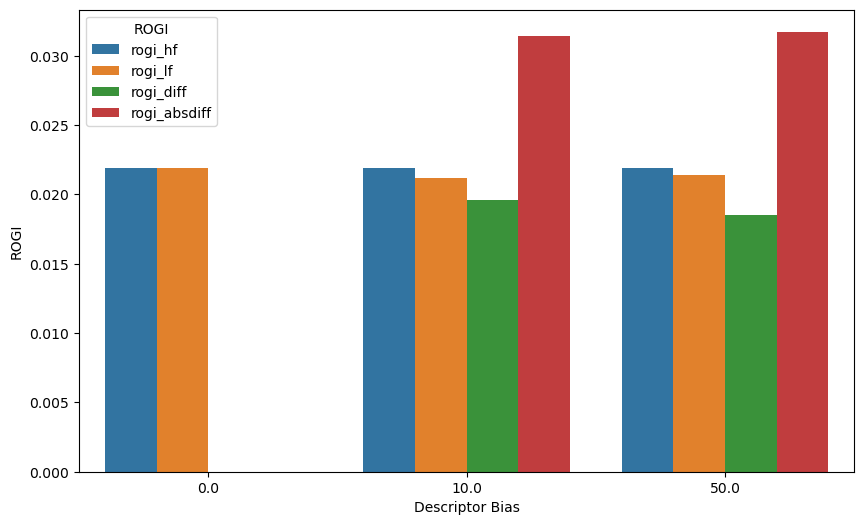

In [8]:
# make a grouped bar plot of the ROGI values for different values of polynomial bias
df_pivot = pd.pivot_table(
	results_df.iloc[[0,1,2,3]],
	values=['rogi_hf', 'rogi_lf', 'rogi_diff', 'rogi_absdiff'],
	index=['add_pn_bias_to_make_lf'],
	aggfunc=np.mean
)

df_pivot = df_pivot.reset_index()
df_pivot = df_pivot.melt(id_vars='add_pn_bias_to_make_lf', value_vars=['rogi_hf', 'rogi_lf', 'rogi_diff', 'rogi_absdiff'], var_name='ROGI', value_name='Value')

plt.figure(figsize=(10, 6))
sns.barplot(x='add_pn_bias_to_make_lf', y='Value', hue='ROGI', data=df_pivot)
plt.xlabel('Polynomial Bias')
plt.ylabel('ROGI')
plt.show()

# make a grouped bar plot of the ROGI values for different values of constant bias
df_pivot = pd.pivot_table(
	results_df.iloc[[0,4,5]],
	values=['rogi_hf', 'rogi_lf', 'rogi_diff', 'rogi_absdiff'],
	index=['add_constant_bias_to_make_lf'],
	aggfunc=np.mean
)

df_pivot = df_pivot.reset_index()
df_pivot = df_pivot.melt(id_vars='add_constant_bias_to_make_lf', value_vars=['rogi_hf', 'rogi_lf', 'rogi_diff', 'rogi_absdiff'], var_name='ROGI', value_name='Value')

plt.figure(figsize=(10, 6))
sns.barplot(x='add_constant_bias_to_make_lf', y='Value', hue='ROGI', data=df_pivot)
plt.xlabel('Constant Bias')
plt.ylabel('ROGI')
plt.show()

# make a grouped bar plot of the ROGI values for different values of Gaussian noise
df_pivot = pd.pivot_table(
	results_df.iloc[[0,6,7]],
	values=['rogi_hf', 'rogi_lf', 'rogi_diff', 'rogi_absdiff'],
	index=['add_gauss_noise_to_make_lf'],
	aggfunc=np.mean
)

df_pivot = df_pivot.reset_index()
df_pivot = df_pivot.melt(id_vars='add_gauss_noise_to_make_lf', value_vars=['rogi_hf', 'rogi_lf', 'rogi_diff', 'rogi_absdiff'], var_name='ROGI', value_name='Value')

plt.figure(figsize=(10, 6))
sns.barplot(x='add_gauss_noise_to_make_lf', y='Value', hue='ROGI', data=df_pivot)
plt.xlabel('Gaussian Noise')
plt.ylabel('ROGI')
plt.show()

# make a grouped bar plot of the ROGI values for different values of descriptor bias
df_pivot = pd.pivot_table(
	results_df.iloc[[0,8,9]],
	values=['rogi_hf', 'rogi_lf', 'rogi_diff', 'rogi_absdiff'],
	index=['add_descriptor_bias_to_make_lf'],
	aggfunc=np.mean
)

df_pivot = df_pivot.reset_index()
df_pivot = df_pivot.melt(id_vars='add_descriptor_bias_to_make_lf', value_vars=['rogi_hf', 'rogi_lf', 'rogi_diff', 'rogi_absdiff'], var_name='ROGI', value_name='Value')

plt.figure(figsize=(10, 6))
sns.barplot(x='add_descriptor_bias_to_make_lf', y='Value', hue='ROGI', data=df_pivot)
plt.xlabel('Descriptor Bias')
plt.ylabel('ROGI')
plt.show()